# Correlation and Causality

Correlation is one of the most used — and most misused — statistics. This lesson covers how to measure it, how to test it, and why it is **not** evidence of cause and effect on its own.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. What is Correlation?

Correlation measures the **strength** and **direction** of a relationship between two quantitative variables. **Pearson's correlation coefficient** measures *linear* association:

$$
r = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}
{\sqrt{\sum_{i=1}^n (x_i - \bar{x})^2} \cdot \sqrt{\sum_{i=1}^n (y_i - \bar{y})^2}}
$$

- $r$ ranges from $-1$ to $+1$: $r = +1$ perfect positive, $r = -1$ perfect negative, $r = 0$ no **linear** relationship.
- **Spearman's $\rho$** is Pearson's $r$ computed on the **ranks**; it captures any *monotonic* relationship and is robust to outliers.
- **Kendall's $\tau$** is another rank-based measure, based on concordant vs discordant pairs.

## 2. Hypothesis Test for Correlation

$H_0: \rho = 0$ vs $H_a: \rho \neq 0$, with test statistic

$$
t = r \sqrt{\frac{n-2}{1-r^2}}, \qquad df = n - 2
$$

## 3. What is Causality?

Causality means **changing one variable directly changes another**. Correlation can arise from:
1. **Direct causation** (A → B)
2. **Reverse causation** (B → A)
3. **Confounding** (a third variable C causes both A and B)
4. **Coincidence** (spurious correlation, especially when many variables are searched)

Only a **randomised experiment** (or careful causal-inference methods) can establish causation.

In [2]:
study_hours <- c(2, 3, 4, 5, 6, 8, 9, 10)
exam_scores <- c(50, 55, 58, 64, 66, 72, 75, 78)

r <- cor(study_hours, exam_scores, method = "pearson")
cat("Pearson r   :", round(r, 4), "\n")
cat("Spearman rho:", round(cor(study_hours, exam_scores, method = "spearman"), 4), "\n")
cat("Kendall tau :", round(cor(study_hours, exam_scores, method = "kendall"), 4), "\n")

n <- length(study_hours)
t_manual <- r * sqrt((n - 2) / (1 - r^2))
cat("Manual t    :", round(t_manual, 3), "\n\n")
cor.test(study_hours, exam_scores, method = "pearson")

Pearson r   : 0.9935 


Spearman rho: 1 


Kendall tau : 1 


Manual t    : 21.375 




	Pearson's product-moment correlation

data:  study_hours and exam_scores
t = 21.375, df = 6, p-value = 6.839e-07
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.9630411 0.9988705
sample estimates:
      cor 
0.9934977 


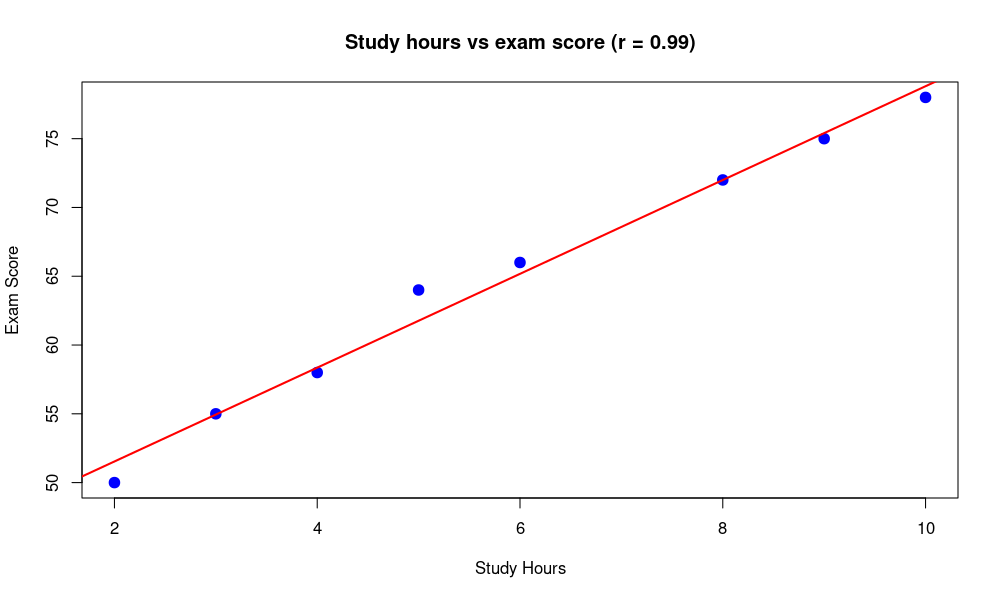

In [3]:
plot(study_hours, exam_scores, pch = 19, cex = 1.4, col = "blue",
     main = sprintf("Study hours vs exam score (r = %.2f)", r),
     xlab = "Study Hours", ylab = "Exam Score")
abline(lm(exam_scores ~ study_hours), col = "red", lwd = 2)

## 4. Always Plot Your Data: Anscombe's Quartet

Anscombe's four datasets (built into R) have **nearly identical** means, variances and correlation ($r \approx 0.816$), yet completely different shapes.

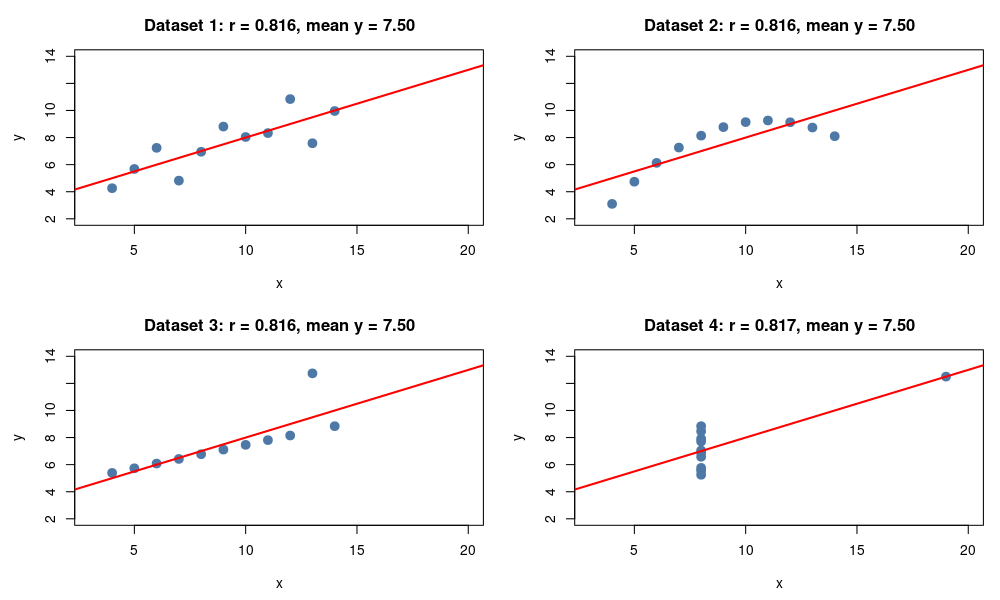

In [4]:
par(mfrow = c(2, 2), mar = c(4.5, 4.5, 3, 1))
for (i in 1:4) {
  x <- anscombe[[paste0("x", i)]]; y <- anscombe[[paste0("y", i)]]
  plot(x, y, pch = 19, cex = 1.4, col = "#4E79A7", xlim = c(3, 20), ylim = c(2, 14),
       main = sprintf("Dataset %d: r = %.3f, mean y = %.2f", i, cor(x, y), mean(y)))
  abline(lm(y ~ x), col = "red", lwd = 2)
}

*Insight: Only dataset 1 is a real linear relationship. Dataset 2 is a curve, dataset 3 is a perfect line pulled off by one outlier, and in dataset 4 a single point creates the entire "correlation". The number alone would have fooled you in three cases out of four.*

## 5. Pearson vs Spearman With Outliers and Curves

In [5]:
set.seed(18)
x <- 1:30
y_curve <- exp(x / 6) + rnorm(30, 0, 2)                 # monotonic but non-linear
y_out   <- 2 * x + rnorm(30, 0, 4); y_out[30] <- -40    # linear + one bad outlier

data.frame(case = c("Monotonic curve", "Linear + one outlier"),
           pearson  = round(c(cor(x, y_curve), cor(x, y_out)), 3),
           spearman = round(c(cor(x, y_curve, method = "spearman"), cor(x, y_out, method = "spearman")), 3))

case,pearson,spearman
<chr>,<dbl>,<dbl>
Monotonic curve,0.856,0.962
Linear + one outlier,0.534,0.786


## 6. Confounding: Ice Cream and Drowning

We simulate a summer: **temperature** drives both ice-cream sales and the number of swimmers (and therefore drownings). Ice cream has **no** effect on drowning in this simulation — yet the two are strongly correlated.

cor(ice cream, drownings)            : 0.605 


partial cor | controlling temperature: 0.048 


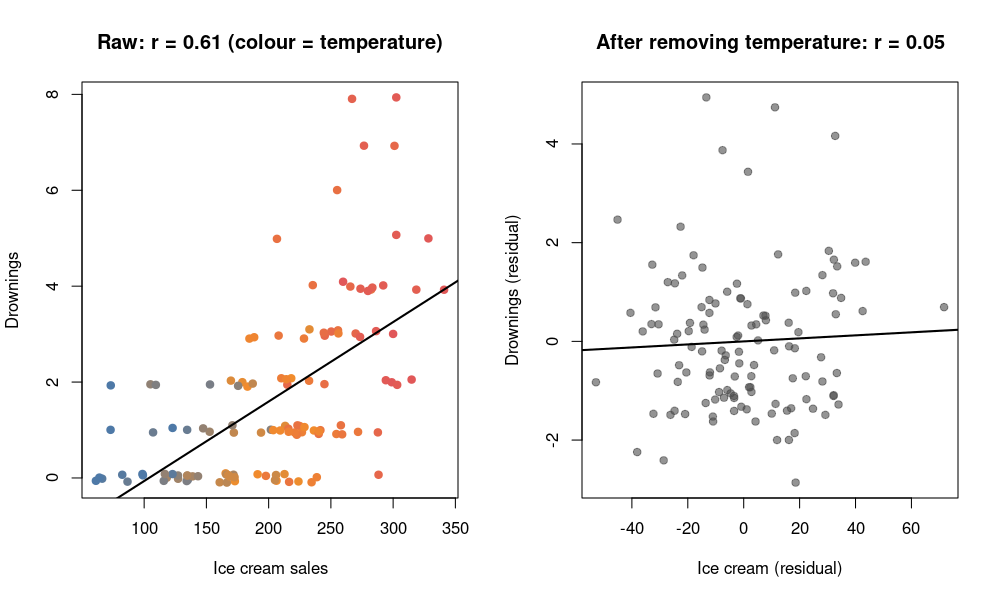

In [6]:
set.seed(42)
days <- 120
temperature <- runif(days, 10, 35)
ice_cream   <- 20 + 8 * temperature + rnorm(days, 0, 25)        # depends only on temperature
drownings   <- rpois(days, lambda = exp(-2 + 0.1 * temperature)) # depends only on temperature

cat("cor(ice cream, drownings)            :", round(cor(ice_cream, drownings), 3), "\n")

# Partial correlation: correlate what's left after removing temperature from both variables
res_ice   <- resid(lm(ice_cream ~ temperature))
res_drown <- resid(lm(drownings ~ temperature))
cat("partial cor | controlling temperature:", round(cor(res_ice, res_drown), 3), "\n")

par(mfrow = c(1, 2))
cols <- colorRampPalette(c("#4E79A7", "#F28E2B", "#E15759"))(100)[cut(temperature, 100)]
plot(ice_cream, jitter(drownings, 0.5), pch = 19, col = cols,
     main = sprintf("Raw: r = %.2f (colour = temperature)", cor(ice_cream, drownings)),
     xlab = "Ice cream sales", ylab = "Drownings")
abline(lm(drownings ~ ice_cream), lwd = 2)
plot(res_ice, res_drown, pch = 19, col = adjustcolor("grey30", 0.6),
     main = sprintf("After removing temperature: r = %.2f", cor(res_ice, res_drown)),
     xlab = "Ice cream (residual)", ylab = "Drownings (residual)")
abline(lm(res_drown ~ res_ice), lwd = 2)

## 7. Correlation Matrix of Many Variables

       mpg    hp    wt  qsec  drat  disp
mpg   1.00 -0.78 -0.87  0.42  0.68 -0.85
hp   -0.78  1.00  0.66 -0.71 -0.45  0.79
wt   -0.87  0.66  1.00 -0.17 -0.71  0.89
qsec  0.42 -0.71 -0.17  1.00  0.09 -0.43
drat  0.68 -0.45 -0.71  0.09  1.00 -0.71
disp -0.85  0.79  0.89 -0.43 -0.71  1.00


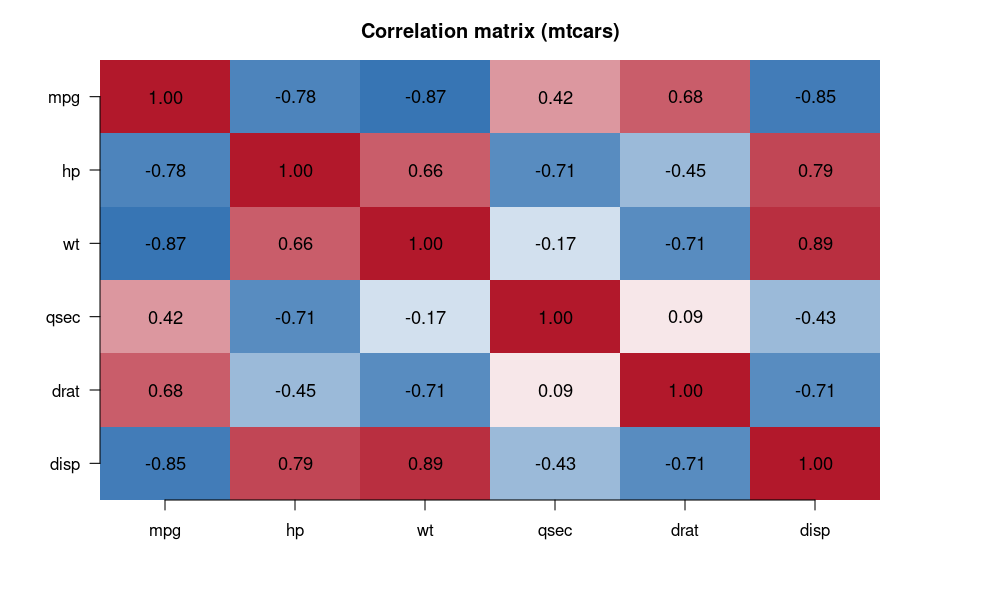

In [7]:
vars <- mtcars[, c("mpg", "hp", "wt", "qsec", "drat", "disp")]
cm <- cor(vars)
print(round(cm, 2))

par(mfrow = c(1, 1), mar = c(5, 5, 3, 6))
pal <- colorRampPalette(c("#2166AC", "white", "#B2182B"))(41)
image(1:ncol(cm), 1:ncol(cm), cm[, ncol(cm):1], col = pal, zlim = c(-1, 1), axes = FALSE,
      xlab = "", ylab = "", main = "Correlation matrix (mtcars)")
axis(1, 1:ncol(cm), colnames(cm)); axis(2, 1:ncol(cm), rev(colnames(cm)), las = 1)
for (i in 1:ncol(cm)) for (j in 1:ncol(cm))
  text(i, ncol(cm) - j + 1, sprintf("%.2f", cm[i, j]), cex = 1.1)

## Real-World Use Case or Analogy

- **Correlation**: ice cream sales and drowning incidents both rise in summer. They are correlated, but one doesn't cause the other — **temperature** is the hidden factor (confounder).
- **Reverse causation**: cities with more police officers have more crime — not because police cause crime, but because high-crime cities hire more police.
- **Causation**: flipping a light switch turns on the light. You can verify it by intervening: flip it and see.

This is why medicine relies on **randomised controlled trials**: random assignment breaks the link between the treatment and every possible confounder, so any remaining difference must be caused by the treatment.